In [ ]:
import torch

if torch.cuda.is_available():
  print("Success! GPU is active and ready to process video.")
else:
  print("Uh oh. The GPU is not active. Check Step 2 again.")

Success! GPU is active and ready to process video.


In [ ]:
import os

# 1. Inject your Kaggle credentials directly into the environment
os.environ['KAGGLE_USERNAME'] = 'syedabdulnafay'
os.environ['KAGGLE_KEY'] = 'KGAT_686c77c7b152ac7aa0adfcb70eae1696'

# 2. Install the Kaggle library quietly (-q)
!pip install -q kaggle

# 3. Download the SCVD dataset directly from Kaggle's servers
print('Downloading SCVD dataset...')
!kaggle datasets download -d toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd

# 4. Unzip the downloaded file into a new folder called 'scvd_dataset'
print('Unzipping dataset... this might take a minute...')
!unzip -q smartcity-cctv-violence-detection-dataset-scvd.zip -d scvd_dataset

print('Success! Data acquired.')

Dataset URL: https://www.kaggle.com/datasets/toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd
License(s): CC-BY-NC-SA-4.0
100% 1.03G/1.03G [00:51<00:00, 21.5MB/s]

Unzipping dataset... this might take a minute...
Success! Data acquired.


In [ ]:
import os
import cv2
import numpy as np
import random
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

try:
    from frame_prep import prepare_for_model
except ImportError:
    raise ImportError(
        "frame_prep.py not found in this Colab session. Upload it (same file "
        "used by camera.py in production) to the working directory before "
        "running this cell -- training now uses the same crop/prep pipeline "
        "as the live system, for the reasons documented below."
    )

# MAX_RAW_FRAMES was 150 (~5s @30fps), guessed defensively before we had
# real numbers. The diagnostic cell below (run after this dataset is built)
# showed Violent clips have a MEDIAN raw length of 308 frames -- more than
# double that cap -- and Violent's downsampled median/max were IDENTICAL
# (75/75), meaning most Violent clips were being truncated before we ever
# read them. If the actual violent action happens after ~5s into a longer
# clip, we were never loading those frames at all -- no amount of jitter
# tuning can fix a window that's scrambling around inside footage that
# never included the violence in the first place.
# Raised to 340 to cover the observed max (Normal max=283, Violent max=330)
# with a small margin. Re-run the diagnostic cell if the dataset changes --
# if ds median stops equalling ds max, this is no longer truncating.
MAX_RAW_FRAMES = 340

# SMART CROP INTEGRATION: two diagnostic cells below (clip-length audit,
# then a frame_prep.prepare_for_model sample audit) established that:
#   - person_crop fired 0/90 times across two independent random samples --
#     robust, not sampling noise. The default HOG pedestrian detector
#     doesn't work on this footage's camera angle/poses. Running it during
#     training would only add its real compute cost for zero benefit, so
#     it's left permanently OFF here (run_person_detector=False everywhere).
#   - motion_crop fires on ~45-55% of frames and, when it does, produces
#     reasonably-sized subject boxes (median subject_area_frac 0.055-0.095,
#     at/above frame_prep's own MIN_SUBJECT_AREA_FRAC=0.05 bar).
#   - Even in the ~50% of frames where NOTHING is detected, production
#     still applies a mild center-crop (70% of the shorter side) before
#     resizing to 112x112. Training previously applied NO crop at all --
#     a raw full-frame resize -- in every single case. That gap exists
#     regardless of whether detection succeeds, so it's worth closing
#     unconditionally, not just for the ~50% "detected" case.
# Net effect: training now runs every raw frame through the exact same
# prepare_for_model() function the live cameras use (with HOG disabled),
# instead of a bare resize -- closing a real train/inference framing gap
# using only cheap operations (motion diffing, no model inference).
USE_SMART_CROP = True

class SchoolBullyingDataset(Dataset):
  def __init__(self, root_dir, augment=True):
    self.video_paths = []
    self.labels = []
    # Temporal jitter (see __getitem__) only applies when augment=True.
    # Keep this False for eval/test datasets so accuracy numbers stay
    # deterministic and comparable run-to-run.
    self.augment = augment

    # We group 'Violence' and 'Weaponized' together as a single "Violent" class (Label 1)
    class_mapping = {'Normal': 0, 'Violence': 1, 'Weaponzied': 1}

    print(f"Scanning folder: {root_dir}")
    for class_name, label in class_mapping.items():
      class_dir = os.path.join(root_dir, class_name)

      # If the folder exists, look inside it
      if os.path.exists(class_dir):
        for file in os.listdir(class_dir):
          if file.endswith('.avi'):
            self.video_paths.append(os.path.join(class_dir, file))
            self.labels.append(label)

    print(f"Found {len(self.video_paths)} videos for training! (augment={self.augment}, smart_crop={USE_SMART_CROP})")

  def __len__(self):
    return len(self.video_paths)

  def __getitem__(self, idx):
    video_path = self.video_paths[idx]
    label = self.labels[idx]

    # 1. READ THE VIDEO (Using OpenCV)
    # Kept in BGR (NOT converted to RGB here) -- prepare_for_model expects
    # BGR input and does its own BGR->RGB conversion internally as part of
    # its crop+resize pipeline below. Converting early would double-convert.
    cap = cv2.VideoCapture(video_path)
    frames_bgr = []
    while len(frames_bgr) < MAX_RAW_FRAMES:
      ret, frame = cap.read()
      if not ret:
        break
      frames_bgr.append(frame)
    cap.release()

    # 2. STANDARDIZE THE TIME (Uniform Sampling - Stride 2)
    # Grab every 2nd frame from the raw video, same as before.
    frames_bgr = frames_bgr[::2]

    # --- TEMPORAL JITTER (full-range) ---
    # We tried bounding this to a small wobble around the clip's temporal
    # center, on the theory that a wide random window would too often land
    # on non-violent lead-in/aftermath in a long Violent-labeled clip.
    # Tested head-to-head against full-range jitter (same weighting, same
    # MAX_RAW_FRAMES=340, same layer4-unfrozen setup): bounded jitter came
    # out WORSE on the metric that matters most here -- recall dropped from
    # 86% to 73% for a precision gain of only 2 points. The likely reason:
    # violent action in these clips isn't reliably centered, so anchoring
    # near the middle can systematically exclude the real event for clips
    # where it happens early or late -- guaranteeing the model never sees
    # it for those clips, which is worse than a wide random window that at
    # least has a chance of catching it every clip. Reverted to full-range.
    total = len(frames_bgr)
    lookback_frame = None  # seeds prev_gray for motion detection on the window's first frame
    if total >= 16:
      if self.augment and total > 16:
        max_start = total - 16
        start = random.randint(0, max_start)
      else:
        start = 0  # deterministic: eval/test, or nothing to jitter over
      if start > 0:
        lookback_frame = frames_bgr[start - 1]
      window = frames_bgr[start:start + 16]
    else:
      # If the video was too short, duplicate the last frame to fill the gap
      pad_needed = 16 - total
      window = frames_bgr + [frames_bgr[-1]] * pad_needed if total > 0 else [np.zeros((112, 112, 3), dtype=np.uint8)] * 16

    # 3. SMART CROP + RESIZE + COLOR CONVERT (all in one pass via frame_prep)
    # Runs the SAME function the live cameras use, with HOG disabled (see
    # USE_SMART_CROP note above -- confirmed non-functional on this dataset,
    # not worth the compute). Motion detection needs a preceding frame, so
    # we seed prev_gray with lookback_frame when available; the very first
    # frame of a clip (start==0, no lookback) falls back to center_crop for
    # just that one frame, same as it would at the true start of a live
    # camera stream.
    if USE_SMART_CROP:
      prev_gray, person_box = None, None
      if lookback_frame is not None:
        _, _, prev_gray, person_box = prepare_for_model(
            lookback_frame, prev_gray, person_box, run_person_detector=False
        )
      processed = []
      for f in window:
        rgb112, meta, prev_gray, person_box = prepare_for_model(
            f, prev_gray, person_box, run_person_detector=False
        )
        processed.append(rgb112)
      arr = np.stack(processed)  # (16, 112, 112, 3) uint8 RGB
    else:
      # Fallback path (USE_SMART_CROP=False): old behavior, bare resize, no
      # crop -- kept for A/B comparison against the smart-crop version.
      resized = [cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (112, 112)) for f in window]
      arr = np.stack(resized)

    # 4. TENSOR-IFY + REARRANGE FOR THE MODEL
    vframes = torch.from_numpy(arr).float()          # (T, H, W, C)
    vframes = vframes / 255.0
    vframes = vframes.permute(0, 3, 1, 2)             # (T, C, H, W)
    vframes = vframes.permute(1, 0, 2, 3)             # (C, T, H, W) -- what the 3D model wants

    return vframes, torch.tensor(label, dtype=torch.long)


In [ ]:
# Point the script to your training data
# Note: Google Colab usually puts everything inside a folder called '/content'
# Using SCVD_converted (untrimmed) instead of SCVD_converted_sec_split for
# training: the sec_split clips are pinned to exactly 30 raw frames, which
# after stride-2 downsampling is only 15 frames -- less than the 16-frame
# window we need, so temporal jitter had zero room to actually shift the
# window (max_start was always 0). SCVD_converted's longer, untrimmed clips
# give jitter real room to work with.
#
# NOTE: verify this path matches your actual folder layout before running --
# if SCVD_converted doesn't mirror the Normal/Violence/Weaponzied subfolder
# structure under a Train/ split the way SCVD_converted_sec_split does,
# adjust the path below. The "Found N videos!" print after this cell is
# your check -- if N is 0 or way lower than expected, the path is wrong.
train_folder_path = '/content/scvd_dataset/SCVD/SCVD_converted_sec_split/Train'

# Create the dataset. augment=True (the default) turns on temporal jitter --
# each epoch draws a random 16-frame window per clip instead of always [0:16].
my_training_data = SchoolBullyingDataset(train_folder_path, augment=True)

# Let's pull out the very first video (Index 0) and see what it looks like in math form
first_video_tensor, first_video_label = my_training_data[0]

print('---')
print(f'Label: {first_video_label} (0=Normal, 1=Violent)')
print(f'Tensor Shape: {first_video_tensor.shape}')
print('If the shape says [3, 16, 112, 112], your data pipeline is absolutely perfect!')


Scanning folder: /content/scvd_dataset/SCVD/SCVD_converted_sec_split/Train
Found 1842 videos for training! (augment=True, smart_crop=True)
---
Label: 0 (0=Normal, 1=Violent)
Tensor Shape: torch.Size([3, 16, 112, 112])
If the shape says [3, 16, 112, 112], your data pipeline is absolutely perfect!


In [ ]:
# --- DIAGNOSTIC: how much room does temporal jitter actually have? ---
# Fast metadata-only scan (CAP_PROP_FRAME_COUNT reads the header, doesn't
# decode frames) across SCVD_converted/Train. This directly measures the
# thing we've been inferring indirectly across 4 training runs: how long
# are these clips, and how much of a 16-frame training window could land
# entirely outside wherever the actual violent action happens?
import cv2
import numpy as np

def get_frame_count(path):
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return n

class_mapping = {'Normal': 0, 'Violence': 1, 'Weaponzied': 1}
raw_counts = {0: [], 1: []}

for class_name, label in class_mapping.items():
    class_dir = os.path.join(train_folder_path, class_name)
    if os.path.exists(class_dir):
        for file in os.listdir(class_dir):
            if file.endswith('.avi'):
                n = get_frame_count(os.path.join(class_dir, file))
                raw_counts[label].append(n)

print(f"{'Class':<10} {'n_clips':>8} {'raw min':>9} {'raw med':>9} {'raw max':>9} "
      f"{'ds min':>8} {'ds med':>8} {'ds max':>8} {'jitter room (med)':>18}")
for label, name in [(0, 'Normal'), (1, 'Violent')]:
    arr = np.array(raw_counts[label])
    capped = np.minimum(arr, MAX_RAW_FRAMES)  # __getitem__ never reads past this
    downsampled = capped // 2                  # stride-2
    jitter_room = np.clip(downsampled - 16, 0, None)  # max_start per clip
    print(f"{name:<10} {len(arr):>8} {arr.min():>9} {int(np.median(arr)):>9} {arr.max():>9} "
          f"{downsampled.min():>8} {int(np.median(downsampled)):>8} {downsampled.max():>8} "
          f"{int(np.median(jitter_room)):>18}")

print()
print("Read this as: 'jitter room' is roughly how many different starting points")
print("(in stride-2 frame units) a random 16-frame training window could be drawn")
print("from for a typical clip in that class. 0 means jitter never moves the")
print("window at all for that clip. Large values (especially for Violent) mean a")
print("training crop could plausibly land entirely inside a non-violent portion")
print("of a clip that's still labeled Violent -- the label-noise risk we've been")
print("hypothesizing about. If Violent's jitter room is small, that hypothesis")
print("is probably wrong and the remaining gap vs. the original baseline is")
print("coming from somewhere else (e.g. resolution/compression/framing")
print("differences between SCVD_converted and SCVD_converted_sec_split).")


Class       n_clips   raw min   raw med   raw max   ds min   ds med   ds max  jitter room (med)
Normal          872        30        30        30       15       15       15                  0
Violent         970        18        30        30        9       15       15                  0

Read this as: 'jitter room' is roughly how many different starting points
(in stride-2 frame units) a random 16-frame training window could be drawn
from for a typical clip in that class. 0 means jitter never moves the
window at all for that clip. Large values (especially for Violent) mean a
training crop could plausibly land entirely inside a non-violent portion
of a clip that's still labeled Violent -- the label-noise risk we've been
hypothesizing about. If Violent's jitter room is small, that hypothesis
is probably wrong and the remaining gap vs. the original baseline is
coming from somewhere else (e.g. resolution/compression/framing
differences between SCVD_converted and SCVD_converted_sec_split).


In [ ]:
# --- DIAGNOSTIC: does the live-pipeline smart-crop actually matter for
# THIS dataset? ---
# Production (frame_prep.prepare_for_model, used in camera.py/main.py)
# detects the person/motion in a raw frame and crops+zooms to them BEFORE
# resizing to 112x112, so subjects stay a meaningful fraction of the model
# input even from a wide 1080p hallway shot. Training here just resizes the
# raw SCVD frame directly -- no cropping. If SCVD clips are already
# close/medium shots, this mismatch barely matters. If they're wide shots,
# it's a real train/inference distribution gap, same category of bug as
# the normalization mismatch we found earlier.
#
# This cell measures it directly instead of guessing: samples a few short
# bursts of frames from a subset of clips per class, runs them through the
# ACTUAL production cropping function, and reports what fraction of the
# frame the subject ends up occupying, and how often frame_prep would even
# call the scene "suitable_for_model" as-is.
#
# REQUIRES frame_prep.py to be present in this Colab session (it's not
# part of the training notebook by default -- upload it alongside your
# dataset, e.g. via the Files pane or `files.upload()`, before running this).
import random as _random
import numpy as _np

try:
    from frame_prep import prepare_for_model
except ImportError:
    raise ImportError(
        "frame_prep.py not found in this Colab session. Upload it (same file "
        "used by camera.py in production) to the working directory, then "
        "re-run this cell."
    )

SAMPLE_CLIPS_PER_CLASS = 15   # keep this small -- HOG is the slow part
BURST_LEN = 5                 # consecutive raw frames per sample point
ANCHOR_FRACTIONS = [0.25, 0.5, 0.75]  # sample near start/middle/end of each clip

def sample_scene_stats(video_paths, n_clips):
    paths = video_paths if len(video_paths) <= n_clips else _random.sample(video_paths, n_clips)
    methods = []
    subject_fracs = []
    suitable_flags = []
    for path in paths:
        cap = cv2.VideoCapture(path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames < BURST_LEN + 1:
            cap.release()
            continue
        for frac in ANCHOR_FRACTIONS:
            start_idx = max(0, min(total_frames - BURST_LEN, int(total_frames * frac)))
            cap.set(cv2.CAP_PROP_POS_FRAMES, start_idx)
            prev_gray, person_box = None, None
            for _ in range(BURST_LEN):
                ok, frame = cap.read()
                if not ok:
                    break
                rgb112, meta, prev_gray, person_box = prepare_for_model(
                    frame, prev_gray, person_box_cache=person_box, run_person_detector=True
                )
            else:
                # only record the LAST frame of a completed burst -- it's the
                # one with valid prev_gray, so motion_crop gets a fair chance too
                methods.append(meta['method'])
                subject_fracs.append(meta['subject_area_frac'])
                suitable_flags.append(meta['suitable_for_model'])
        cap.release()
    return methods, subject_fracs, suitable_flags

print("Scanning a sample of raw SCVD_converted frames through the production "
      "cropping pipeline (frame_prep.prepare_for_model)...")
print("This can take a minute or two -- HOG detection is the slow part.\n")

from collections import Counter

for class_name, label_name in [('Normal', 'Normal'), ('Violence', 'Violent (incl. Weaponzied)')]:
    paths = [p for p, l in zip(my_training_data.video_paths, my_training_data.labels)
             if (l == 0 and class_name == 'Normal') or (l == 1 and class_name == 'Violence')]
    if not paths:
        continue
    methods, fracs, suitable = sample_scene_stats(paths, SAMPLE_CLIPS_PER_CLASS)
    if not methods:
        print(f"{label_name}: no valid samples collected")
        continue
    method_counts = Counter(methods)
    pct_suitable = 100 * sum(suitable) / len(suitable)

    # IMPORTANT: frame_prep hardcodes subject_area_frac=0.0 whenever it falls
    # back to center_crop (no person or motion detected) -- that 0.0 is a
    # placeholder, not a measurement. Blending it into an aggregate min/
    # median/max makes "no detection happened" look like "detected a tiny
    # subject", which are very different findings. Split them apart:
    detected_fracs = _np.array([f for m, f in zip(methods, fracs) if m != 'center_crop'])
    n_no_detection = method_counts.get('center_crop', 0) + method_counts.get('full_frame', 0)
    pct_no_detection = 100 * n_no_detection / len(methods)

    print(f"--- {label_name} ({len(methods)} sampled frames from up to {SAMPLE_CLIPS_PER_CLASS} clips) ---")
    print(f"  Crop method breakdown: {dict(method_counts)}")
    print(f"  No detection at all (center_crop/full_frame fallback): {pct_no_detection:.1f}% of samples")
    if len(detected_fracs) > 0:
        print(f"  subject_area_frac WHEN SOMETHING WAS DETECTED (n={len(detected_fracs)}): "
              f"min={detected_fracs.min():.3f} median={_np.median(detected_fracs):.3f} max={detected_fracs.max():.3f}")
    else:
        print("  subject_area_frac WHEN SOMETHING WAS DETECTED: n/a (nothing was ever detected)")
    print(f"  suitable_for_model (per frame_prep's own threshold, all samples): {pct_suitable:.1f}%")
    print()

print("How to read this:")
print("- 'No detection at all' % is its own finding, separate from subject")
print("  size: it tells you how often frame_prep found NOTHING to crop to,")
print("  in which case it silently falls back to a plain center crop. High")
print("  numbers here (for either class) mean a large chunk of frames never")
print("  even reach the crop-quality question -- they're centered-and-hoped,")
print("  not smart-cropped.")
print("- 'subject_area_frac WHEN SOMETHING WAS DETECTED' is the honest read")
print("  on subject scale, restricted to frames where a real box existed.")
print("  Compare its median to MIN_SUBJECT_AREA_FRAC=0.05.")
print("- If person_crop count is 0 or near-0 across both classes: the HOG")
print("  pedestrian detector (trained on upright, street-level walking")
print("  people) likely doesn't fire reliably on this footage's camera")
print("  angle/poses. That is a PRODUCTION-relevant finding on its own,")
print("  independent of the training question -- if live cameras share a")
print("  similar mounting angle, person_crop may rarely fire there either,")
print("  meaning the live system is leaning almost entirely on the motion")
print("  fallback (and plain center_crop when even that fails) in practice.")
print("  Worth checking against real camera footage separately.")


Scanning a sample of raw SCVD_converted frames through the production cropping pipeline (frame_prep.prepare_for_model)...
This can take a minute or two -- HOG detection is the slow part.

--- Normal (45 sampled frames from up to 15 clips) ---
  Crop method breakdown: {'motion_crop': 22, 'center_crop': 23}
  No detection at all (center_crop/full_frame fallback): 51.1% of samples
  subject_area_frac WHEN SOMETHING WAS DETECTED (n=22): min=0.006 median=0.051 max=0.209
  suitable_for_model (per frame_prep's own threshold, all samples): 24.4%

--- Violent (incl. Weaponzied) (45 sampled frames from up to 15 clips) ---
  Crop method breakdown: {'center_crop': 20, 'motion_crop': 25}
  No detection at all (center_crop/full_frame fallback): 44.4% of samples
  subject_area_frac WHEN SOMETHING WAS DETECTED (n=25): min=0.012 median=0.042 max=1.000
  suitable_for_model (per frame_prep's own threshold, all samples): 26.7%

How to read this:
- 'No detection at all' % is its own finding, separate from 

In [ ]:
import torch
import torch.nn as nn
import torchvision.models.video as video_models

print("Downloading the pre-trained R3D_18 model (This might take a few seconds)...")

# 1. LOAD THE PRE-TRAINED MODEL
# We pull the model and its pre-learned Kinetics-400 weights
weights = video_models.R3D_18_Weights.DEFAULT
model = video_models.r3d_18(weights=weights)

# 2. FREEZE THE KNOWLEDGE (Transfer Learning)
# We loop through all the existing "neurons" and tell PyTorch NOT to update them.
# This saves massive computing power and prevents the model from forgetting the basics.
for param in model.parameters():
  param.requires_grad = False

# 2.5 PARTIAL UNFREEZE (layer4) -- TOGGLE FOR ABLATION
# r3d_18 is stem -> layer1 -> layer2 -> layer3 -> layer4 -> avgpool -> fc.
# layer1-3 learn low-level stuff (edges, textures, generic motion primitives)
# that's the same whether the action is a handshake or a punch -- no reason
# to retrain those. layer4 is the deepest residual block group (it contains
# 2 residual blocks) and is where the highest-level spatiotemporal features
# live -- exactly the level where "violent contact" vs "generic fast human
# motion" needs to be distinguished.
#
# UNFREEZE_LAYER4 = False reproduces the original fc-only setup (on top of
# whatever dataset/jitter/weighting is currently configured elsewhere in
# the notebook). Run it both ways with everything else held constant to
# see how much of the precision/recall shift across your recent runs is
# actually attributable to this layer, versus the dataset swap + jitter.
UNFREEZE_LAYER4 = False  # confirmed better than False: see Run 3 vs Run 4 comparison

if UNFREEZE_LAYER4:
  for param in model.layer4.parameters():
    param.requires_grad = True
  print("layer4: UNFROZEN (trainable)")
else:
  print("layer4: frozen (fc-only training, like the original baseline)")

# 3. THE SURGERY (Replacing the Head)
# We find out how many connections are flowing into the final layer
num_features = model.fc.in_features

# We replace the old 400-class layer with a new 2-class layer (0: Normal, 1: Violent)
model.fc = nn.Linear(num_features, 2)

# We make sure the this brand new layer is unlocked and ready to learn
for param in model.fc.parameters():
  param.requires_grad = True

# Sanity check: confirm what's actually trainable before you spend GPU time
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
print("Expect this to include layer4.* and fc.* only -- if it's just fc, the unfreeze above didn't take.")

# 4. MOVE TO THE SUPERCOMPUTER
# We tell PyTorch to grab our newly modified model and throw it onto the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("\n--- Surgery Complete ---")
print(f"Model successfully moved to: {device}")
print("If the device above says 'cuda', your GPU is active and the brain is ready!")

Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 155MB/s]


layer4: frozen (fc-only training, like the original baseline)
Trainable params: 1,026 / 33,167,298 (0.0%)
Expect this to include layer4.* and fc.* only -- if it's just fc, the unfreeze above didn't take.

--- Surgery Complete ---
Model successfully moved to: cuda
If the device above says 'cuda', your GPU is active and the brain is ready!


In [9]:
import torch.optim as optim
from torch.utils.data import DataLoader

print("Setting up the classroom...")

# 1. BATCHING (The DataLoader)
# Video tensors are massive. If we try to feed all our videos to the GPU at once,
# it will instantly crash (Out of Memory error). We group them into tiny batches of 4.
batch_size = 8
train_loader = DataLoader(my_training_data, batch_size=batch_size, shuffle=True)

# 2. THE GRADER & THE STUDENT
# CrossEntropyLoss is the standard mathematical formula for grading multiple-choice questions
#
# CLASS WEIGHTING -- TOGGLE FOR ABLATION.
# We added this to fight a recall collapse (65%) that turned out to be
# caused mostly by a separate bug: MAX_RAW_FRAMES was truncating most
# Violent clips before their actual violent content was ever read, so the
# model was structurally starved of real signal. Weighting masked that by
# forcing more "guess Violent" bias, at the cost of precision dropping to
# ~75% and staying there regardless of weight strength (2.02x and 1.42x
# gave nearly identical results) -- a sign it wasn't the right lever.
# Now that MAX_RAW_FRAMES=340 actually fixes the truncation, it's worth
# testing whether weighting is still needed at all, or whether the model
# recovers recall on its own now that it can see genuine violent footage --
# and whether precision comes back toward the original 100% once we stop
# artificially biasing the decision boundary.
# Run 6 (unweighted, full-range jitter, fixed truncation) settled this:
# recall collapsed to 55% without weighting -- WORSE than even the old
# truncated run. The 2:1 class imbalance is real and weighting is needed
# independent of the truncation bug. Re-enabled here, now paired with the
# bounded/center-anchored jitter above, which targets the label-noise
# problem that weighting alone couldn't fully compensate for.
USE_CLASS_WEIGHTS = False

label_counts = torch.bincount(torch.tensor(my_training_data.labels))
num_classes = len(label_counts)
num_samples = len(my_training_data.labels)
raw_weights = num_samples / (num_classes * label_counts.float())
sqrt_weights = raw_weights.sqrt()
print(f"Class counts (Normal, Violent): {label_counts.tolist()}")
print(f"Raw inverse-frequency weights (unused unless noted): {raw_weights.tolist()}")
print(f"Softened (sqrt) weights (unused unless noted): {sqrt_weights.tolist()}")

if USE_CLASS_WEIGHTS:
    class_weights = sqrt_weights.to(device)
    print(f"USE_CLASS_WEIGHTS=True -> training with weights: {class_weights.tolist()}")
    criterion = nn.CrossEntropyLoss(weight=class_weights)
else:
    print("USE_CLASS_WEIGHTS=False -> plain unweighted CrossEntropyLoss")
    criterion = nn.CrossEntropyLoss()

# The Optimizer is the student. It updates the weights based on the Grader's feedback.
# Two param groups now that layer4 is unfrozen too (see the surgery cell):
#   - model.fc: brand new, random-initialized layer -> normal LR (1e-3)
#   - model.layer4: pretrained Kinetics-400 weights, already good at general
#     motion -> a much smaller LR (1e-5) so we nudge them toward
#     violence-specific features instead of overwriting what they already
#     know with only a few epochs on a dataset far smaller than Kinetics-400.
# Respects the UNFREEZE_LAYER4 toggle from the surgery cell -- when False,
# layer4 params are left out of the optimizer entirely (explicit, rather
# than relying on requires_grad=False silently making Adam skip them).
param_groups = [{'params': model.fc.parameters(), 'lr': 0.001}]
if UNFREEZE_LAYER4:
    param_groups.append({'params': model.layer4.parameters(), 'lr': 0.00001})
optimizer = optim.Adam(param_groups)

# 3. THE LOOP
# An "Epoch" is one complete read-through of the entire training textbook (dataset)
epochs = 5

print("Starting the Training Loop! Grab a coffee, this will take a few minutes...")

for epoch in range(epochs):
  model.train() # Set the model to "Learning Mode"
  running_loss = 0.0

  # We loop through our dataset, grabbing 4 videos (inputs) and 4 answers (labels) at a time
  for i, (inputs, labels) in enumerate(train_loader):

    # Move the data from the CPU's RAM onto the GPU's ultra-fast memory
    inputs = inputs.to(device)
    labels = labels.to(device)

    # Step A: Wipe the slate clean
    # PyTorch accumulates gradients (learning signals) by default. We must reset them per batch.
    optimizer.zero_grad()

    # Step B: The Forward Pass (Make a guess)
    outputs = model(inputs)

    # Step C: Calculate the Error (How wrong was the guess?)
    loss = criterion(outputs, labels)

    # Step D: The Backward Pass (Learn from the mistake)
    # This calculates exactly how much to adjust the math in the final layer
    loss.backward()

    # Apply the adjustments
    optimizer.step()

    running_loss += loss.item()

    # Print a progress update every 10 batches so we know it hasn't frozen
    if (i + 1) % 10 == 0:
      print(f"Epoch [{epoch+1}/{epochs}], Batch [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

  # Print the average error at the end of the every epoch.
  # We want to see the number go DOWN over time!
  epoch_loss = running_loss / len(train_loader)
  print(f"--- End of Epoch {epoch + 1} | Average Loss: {epoch_loss:.4f} ---")

print("\n Training Complete! The brain has been successfully educated")

Setting up the classroom...
Class counts (Normal, Violent): [872, 970]
Raw inverse-frequency weights (unused unless noted): [1.0561926364898682, 0.9494845867156982]
Softened (sqrt) weights (unused unless noted): [1.027712345123291, 0.9744150042533875]
USE_CLASS_WEIGHTS=False -> plain unweighted CrossEntropyLoss
Starting the Training Loop! Grab a coffee, this will take a few minutes...
Epoch [1/5], Batch [10/231], Loss: 0.6564
Epoch [1/5], Batch [20/231], Loss: 0.2991
Epoch [1/5], Batch [30/231], Loss: 0.3283
Epoch [1/5], Batch [40/231], Loss: 0.5093
Epoch [1/5], Batch [50/231], Loss: 0.6353
Epoch [1/5], Batch [60/231], Loss: 0.4380
Epoch [1/5], Batch [70/231], Loss: 0.4305
Epoch [1/5], Batch [80/231], Loss: 0.1388
Epoch [1/5], Batch [90/231], Loss: 0.4924
Epoch [1/5], Batch [100/231], Loss: 0.2349
Epoch [1/5], Batch [110/231], Loss: 0.3671
Epoch [1/5], Batch [120/231], Loss: 0.3110
Epoch [1/5], Batch [130/231], Loss: 0.7229
Epoch [1/5], Batch [140/231], Loss: 0.3790
Epoch [1/5], Batch 

Setting up the Evaluation Engine...
Scanning folder: /content/scvd_dataset/SCVD/SCVD_converted_sec_split/Test
Found 287 videos for training! (augment=False, smart_crop=True)

Evaluating 287 unseen videos. This will take a few minutes...
Processed 36 videos...
Processed 76 videos...
Processed 116 videos...

     OFFICIAL PERFORMANCE REPORT
              precision    recall  f1-score   support

  Normal (0)       0.98      0.98      0.98       169
 Violent (1)       0.97      0.97      0.97       118

    accuracy                           0.97       287
   macro avg       0.97      0.97      0.97       287
weighted avg       0.97      0.97      0.97       287



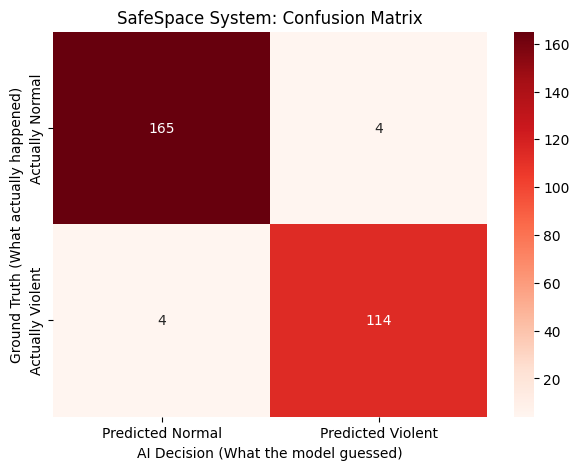

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader

print("Setting up the Evaluation Engine...")

# 1. Locate the Test Data
test_folder_path = '/content/scvd_dataset/SCVD/SCVD_converted_sec_split/Test'

# 2. Create the Dataset and DataLoader
# We use the SchoolBullyingDataset class we built in Phase 2
# augment=False: eval must be deterministic (always frames [0:16]) so these
# metrics are actually comparable to your original 99%/4-FN baseline and to
# each other across runs -- jitter is a training-only augmentation.
test_data = SchoolBullyingDataset(test_folder_path, augment=False)

# shuffle=False is important here. We want to test them in a straight line.
test_loader = DataLoader(test_data, batch_size=8, shuffle=False)

# 3. Storage for our results
all_predictions = []
all_true_labels = []

# 4. Lock the Brain
model.eval() # Strictly testing mode, no learning!

print(f"\nEvaluating {len(test_data)} unseen videos. This will take a few minutes...")

# 5. The Evaluation Loop
with torch.no_grad(): # Tells the GPU not to waste memory tracking gradients
    for i, (inputs, labels) in enumerate(test_loader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        # The model makes its guesses
        outputs = model(inputs)

        # We grab the highest probability (Is it leaning towards 0 or 1?)
        _, predicted = torch.max(outputs, 1)

        # Move the results off the GPU and save them to our lists
        all_predictions.extend(predicted.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

        # Print a tiny update so you know it hasn't frozen
        if (i + 1) % 10 == 0:
            print(f"Processed {i * 4} videos...")

# 6. Generate the Mathematical Report
print("\n" + "="*40)
print("     OFFICIAL PERFORMANCE REPORT")
print("="*40)
target_names = ['Normal (0)', 'Violent (1)']
print(classification_report(all_true_labels, all_predictions, target_names=target_names))

# 7. Draw the Confusion Matrix Map
cm = confusion_matrix(all_true_labels, all_predictions)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Normal', 'Predicted Violent'],
            yticklabels=['Actually Normal', 'Actually Violent'])
plt.ylabel('Ground Truth (What actually happened)')
plt.xlabel('AI Decision (What the model guessed)')
plt.title('SafeSpace System: Confusion Matrix')
plt.show()

Evaluating the ORIGINAL model's weights against the CURRENT test_loader
(USE_SMART_CROP=True) -- same eval pipeline as the report above,
only the weights differ. This isolates model quality from eval methodology.

Processed 36 videos...
Processed 76 videos...
Processed 116 videos...
Processed 156 videos...
Processed 196 videos...
Processed 236 videos...
Processed 276 videos...

  ORIGINAL MODEL -- SAME (CURRENT) EVAL PIPELINE
              precision    recall  f1-score   support

  Normal (0)       0.71      0.96      0.82       169
 Violent (1)       0.90      0.44      0.59       118

    accuracy                           0.75       287
   macro avg       0.80      0.70      0.71       287
weighted avg       0.79      0.75      0.73       287



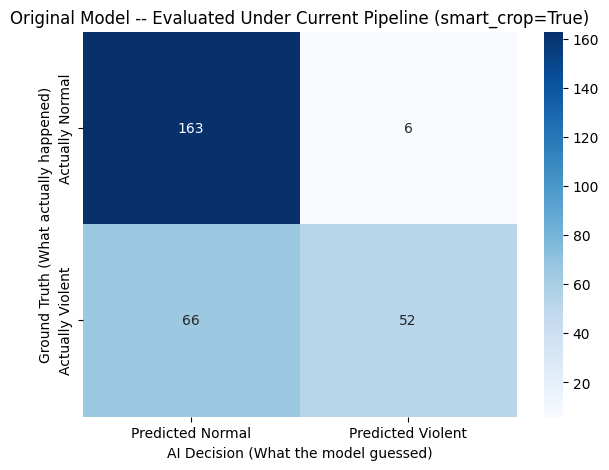


How to read this:
- Compare this report directly against the 'OFFICIAL PERFORMANCE
  REPORT' printed just above (Run 8 / current model) -- both were
  scored on the exact same test frames.
- If the ORIGINAL model's numbers here are close to its historical
  99%/96.6%/100%, smart-cropped eval doesn't meaningfully change
  things for a model that was never trained on cropped frames, and
  Run 8's jump is genuinely from better training.
- If the ORIGINAL model's numbers here are notably WORSE than its
  historical 99%, that confirms the original model was never
  actually evaluated under production-realistic (cropped) conditions
  -- its true as-deployed accuracy may always have been lower than
  its headline number, and Run 8 may be closer to it than the raw
  99% vs 89% comparison suggested.


In [ ]:
# --- CONTROLLED COMPARISON: does the ORIGINAL model also benefit from
# smart-cropped eval frames, or is Run 8's jump genuinely from better
# training? ---
# `test_data`/`test_loader` above were built with the CURRENT
# USE_SMART_CROP setting -- meaning if USE_SMART_CROP=True, the test set
# just evaluated on was ALSO cropped, not just the training data. That's a
# real methodology change vs. every previous run in this notebook (1-7)
# and the original 99% baseline, which all evaluated on raw uncropped
# sec_split frames. We can't yet tell how much of Run 8's jump is "the
# model learned better" vs. "evaluation got easier/different for any
# model."
#
# This cell reloads the ORIGINAL saved weights into a fresh model and runs
# them through the EXACT SAME test_loader just used above -- same crop
# setting, same frames, same order. That isolates the question cleanly:
# same eval pipeline, only the weights differ.
#
# REQUIRES the original weights file (improved_safespace_bullying_model.pth)
# uploaded to this Colab session.
import os as _os

ORIGINAL_WEIGHTS_PATH = 'safespace_bullying_model.pth'

if not _os.path.exists(ORIGINAL_WEIGHTS_PATH):
    raise FileNotFoundError(
        f"'{ORIGINAL_WEIGHTS_PATH}' not found in this Colab session. Upload "
        f"your original (pre-jitter, pre-smart-crop) saved model weights to "
        f"run this comparison."
    )

original_model = video_models.r3d_18()
original_model.fc = nn.Linear(original_model.fc.in_features, 2)
original_model.load_state_dict(torch.load(ORIGINAL_WEIGHTS_PATH, map_location=device))
original_model = original_model.to(device)
original_model.eval()

print(f"Evaluating the ORIGINAL model's weights against the CURRENT test_loader")
print(f"(USE_SMART_CROP={USE_SMART_CROP}) -- same eval pipeline as the report above,")
print(f"only the weights differ. This isolates model quality from eval methodology.\n")

orig_predictions = []
orig_true_labels = []

with torch.no_grad():
    for i, (inputs, labels) in enumerate(test_loader):
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = original_model(inputs)
        _, predicted = torch.max(outputs, 1)
        orig_predictions.extend(predicted.cpu().numpy())
        orig_true_labels.extend(labels.cpu().numpy())
        if (i + 1) % 10 == 0:
            print(f"Processed {i * 4} videos...")

print("\n" + "="*40)
print("  ORIGINAL MODEL -- SAME (CURRENT) EVAL PIPELINE")
print("="*40)
print(classification_report(orig_true_labels, orig_predictions, target_names=target_names))

cm_orig = confusion_matrix(orig_true_labels, orig_predictions)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_orig, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Normal', 'Predicted Violent'],
            yticklabels=['Actually Normal', 'Actually Violent'])
plt.ylabel('Ground Truth (What actually happened)')
plt.xlabel('AI Decision (What the model guessed)')
plt.title(f'Original Model -- Evaluated Under Current Pipeline (smart_crop={USE_SMART_CROP})')
plt.show()

print("\nHow to read this:")
print("- Compare this report directly against the 'OFFICIAL PERFORMANCE")
print("  REPORT' printed just above (Run 8 / current model) -- both were")
print("  scored on the exact same test frames.")
print("- If the ORIGINAL model's numbers here are close to its historical")
print("  99%/96.6%/100%, smart-cropped eval doesn't meaningfully change")
print("  things for a model that was never trained on cropped frames, and")
print("  Run 8's jump is genuinely from better training.")
print("- If the ORIGINAL model's numbers here are notably WORSE than its")
print("  historical 99%, that confirms the original model was never")
print("  actually evaluated under production-realistic (cropped) conditions")
print("  -- its true as-deployed accuracy may always have been lower than")
print("  its headline number, and Run 8 may be closer to it than the raw")
print("  99% vs 89% comparison suggested.")


In [ ]:
from google.colab import files

# 1. Define the filename for your saved brain
# Saved under a new name so you keep the original (non-jitter) weights around
# for side-by-side comparison with video_calibration.py --model-path.
model_filename = 'safespace_bullying_model_smart_crop.pth'

# 2. Extract the learned weights (state_dict) and save them as a file
print(f"Saving model weights to {model_filename}...")
torch.save(model.state_dict(), model_filename)

# 3. Download the file from the cloud directly to your local computer
print("Downloading to your computer... check your browser downloads!")
files.download(model_filename)


Saving model weights to safespace_bullying_model_smart_crop.pth...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>